In [ ]:
!pip install pandas numpy matplotlib seaborn plotly wordcloud squarify

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import squarify

from wordcloud import WordCloud
import zipfile
import re

sns.set_theme(style="whitegrid")

# Load ZIP dataset
with zipfile.ZipFile("wine+quality.zip") as z:

    red = pd.read_csv(
        z.open("winequality-red.csv"),
        sep=";"
    )

    white = pd.read_csv(
        z.open("winequality-white.csv"),
        sep=";"
    )

# Add wine type
red["wine_type"] = "Red"
white["wine_type"] = "White"

# Combine datasets
df = pd.concat([red, white], ignore_index=True)

print("Dataset Shape:", df.shape)
print(df.head())
print(df.info())

Dataset Shape: (6497, 13)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality wine_type  
0      9.4        5       Re

In [ ]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicates
print("Duplicate Records:", df.duplicated().sum())

# Remove duplicates
df.drop_duplicates(inplace=True)

# Statistical summary
print(df.describe())

# Check data types
print(df.dtypes)

# Quality distribution
print(df["quality"].value_counts().sort_index())

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64
Duplicate Records: 1177
       fixed acidity  volatile acidity  citric acid  residual sugar  \
count    5320.000000       5320.000000  5320.000000     5320.000000   
mean        7.215179          0.344130     0.318494        5.048477   
std         1.319671          0.168248     0.147157        4.500180   
min         3.800000          0.080000     0.000000        0.600000   
25%         6.400000          0.230000     0.240000        1.800000   
50%         7.000000          0.300000     0.310000        2.700000   
75%         7.700000          0.410000     0.400000        7.500000   
max        15.900000          1.580000   

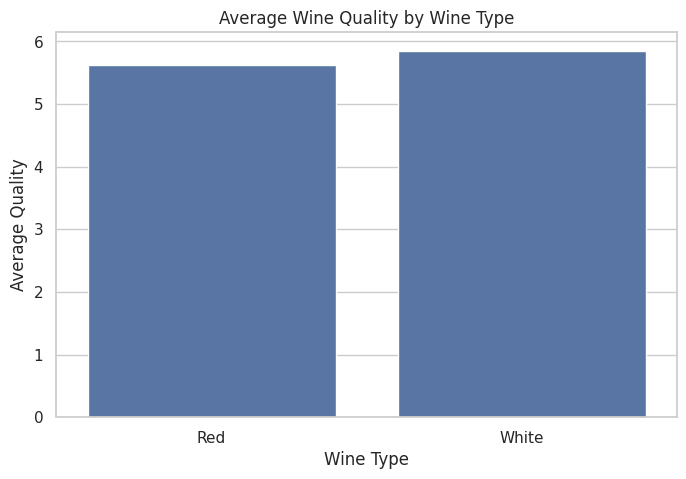

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="wine_type",
    y="quality",
    errorbar=None
)

plt.title("Average Wine Quality by Wine Type")
plt.xlabel("Wine Type")
plt.ylabel("Average Quality")

plt.show()

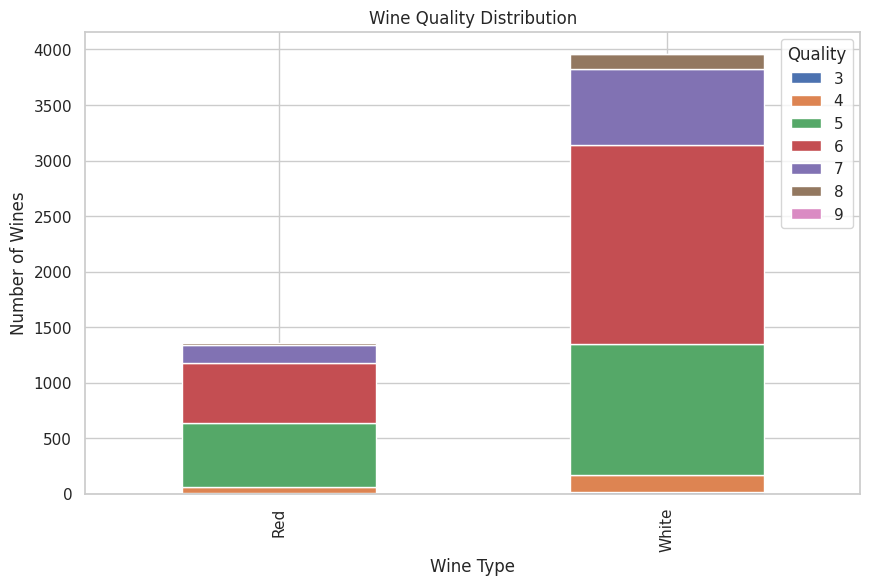

In [ ]:
quality_data = pd.crosstab(
    df["wine_type"],
    df["quality"]
)

quality_data.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6)
)

plt.title("Wine Quality Distribution")
plt.xlabel("Wine Type")
plt.ylabel("Number of Wines")
plt.legend(title="Quality")

plt.show()

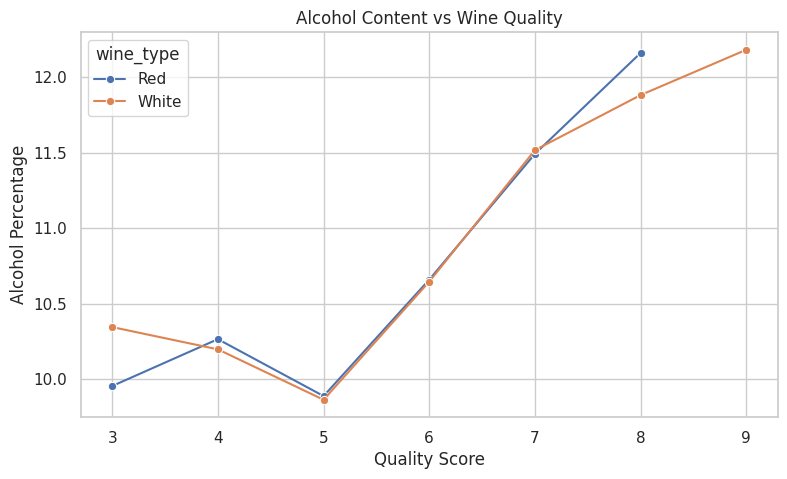

In [ ]:
plt.figure(figsize=(9,5))

sns.lineplot(
    data=df,
    x="quality",
    y="alcohol",
    hue="wine_type",
    marker="o",
    errorbar=None
)

plt.title("Alcohol Content vs Wine Quality")
plt.xlabel("Quality Score")
plt.ylabel("Alcohol Percentage")

plt.show()

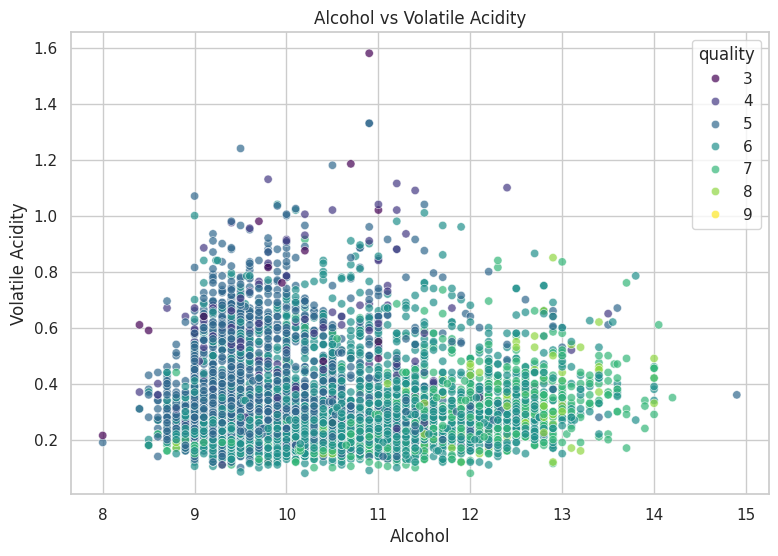

In [ ]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="alcohol",
    y="volatile acidity",
    hue="quality",
    palette="viridis",
    alpha=0.7
)

plt.title("Alcohol vs Volatile Acidity")
plt.xlabel("Alcohol")
plt.ylabel("Volatile Acidity")

plt.show()

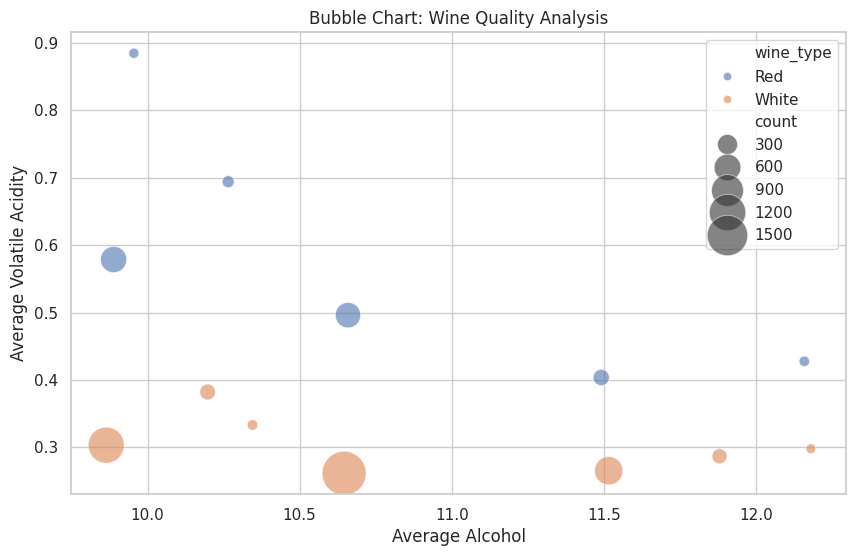

In [ ]:
bubble_data = df.groupby(
    ["quality", "wine_type"]
).agg(
    alcohol=("alcohol", "mean"),
    acidity=("volatile acidity", "mean"),
    count=("quality", "size")
).reset_index()

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=bubble_data,
    x="alcohol",
    y="acidity",
    size="count",
    hue="wine_type",
    sizes=(50, 1000),
    alpha=0.6
)

plt.title("Bubble Chart: Wine Quality Analysis")
plt.xlabel("Average Alcohol")
plt.ylabel("Average Volatile Acidity")

plt.show()

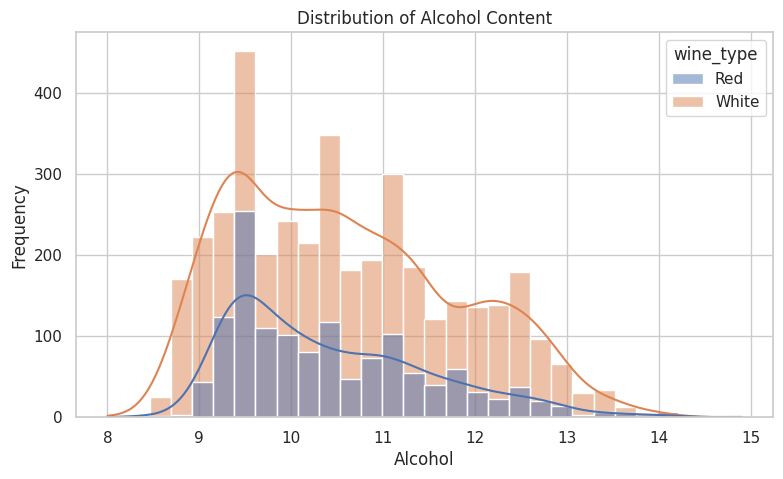

In [ ]:
plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x="alcohol",
    bins=30,
    kde=True,
    hue="wine_type"
)

plt.title("Distribution of Alcohol Content")
plt.xlabel("Alcohol")
plt.ylabel("Frequency")

plt.show()

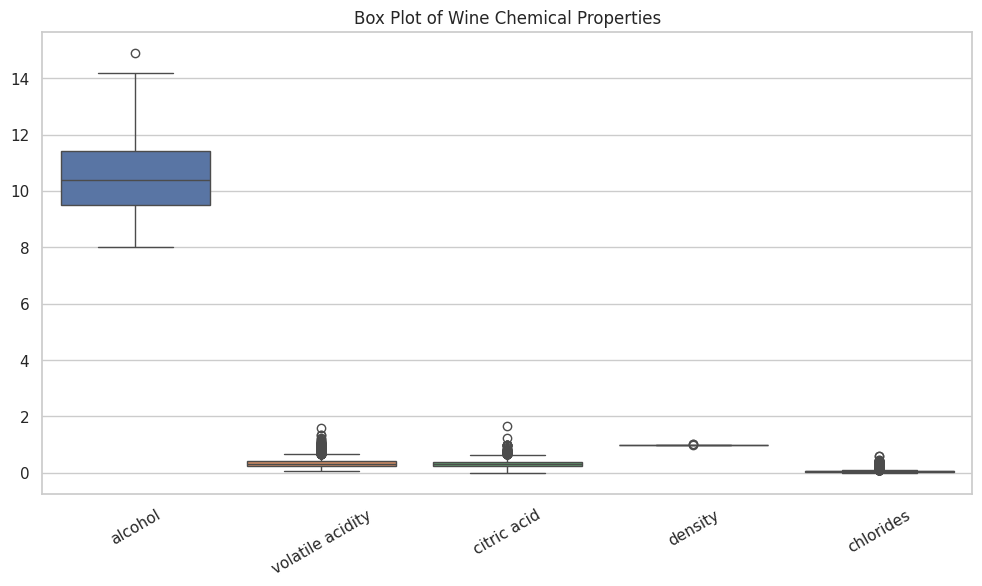

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df[
        ["alcohol", "volatile acidity",
         "citric acid", "density", "chlorides"]
    ]
)

plt.title("Box Plot of Wine Chemical Properties")
plt.xticks(rotation=30)

plt.show()

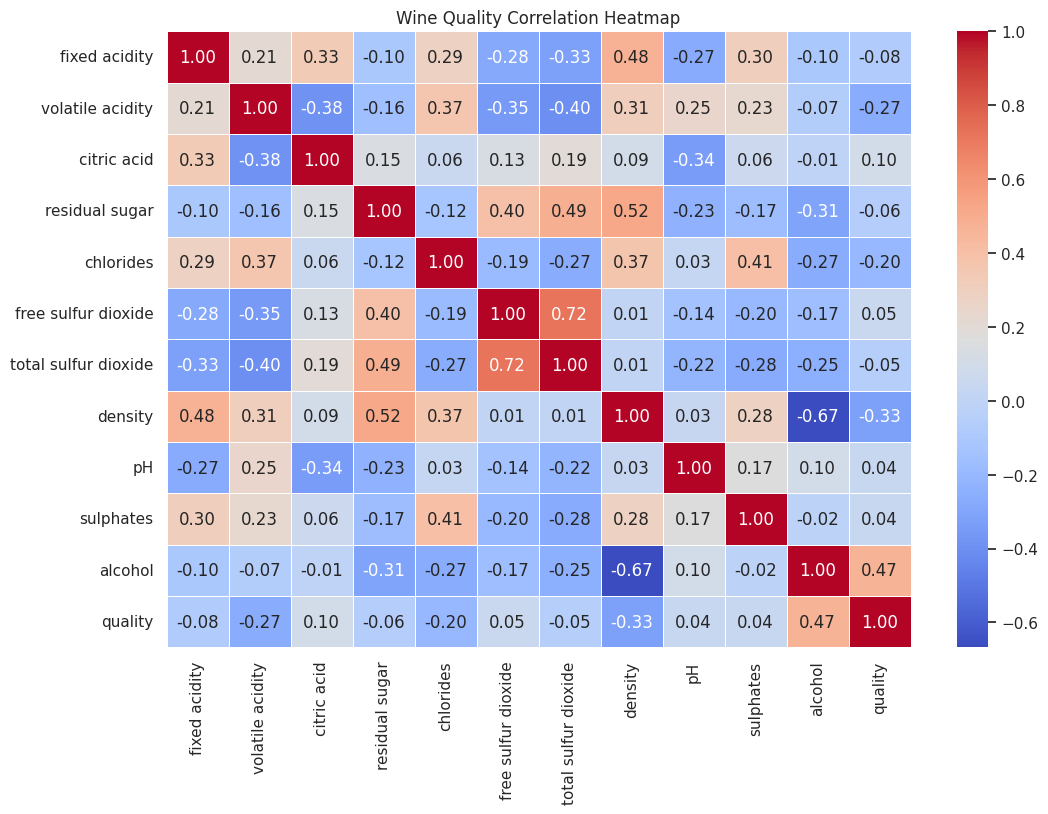

In [ ]:
plt.figure(figsize=(12,8))

corr = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Wine Quality Correlation Heatmap")

plt.show()

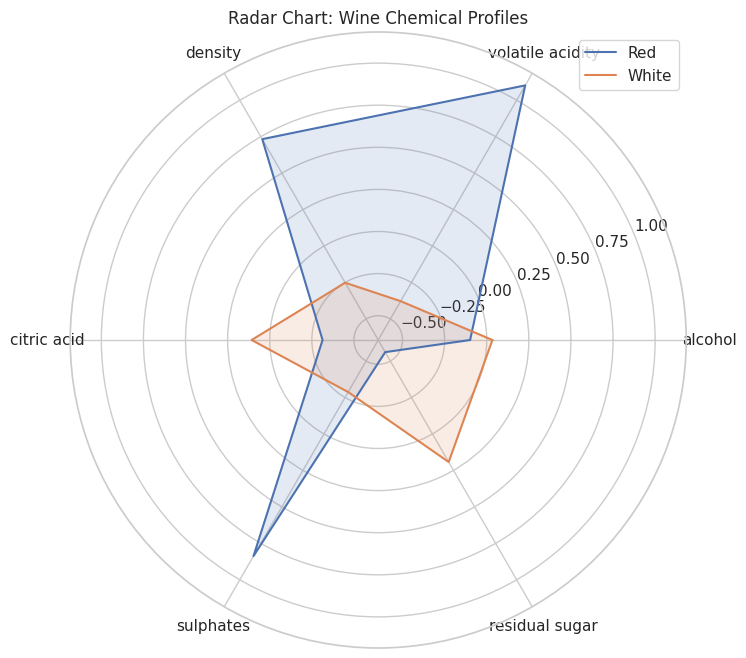

In [ ]:
features = [
    "alcohol",
    "volatile acidity",
    "density",
    "citric acid",
    "sulphates",
    "residual sugar"
]

# Standardize features for fair comparison
means = df.groupby("wine_type")[features].mean()

std_means = (
    means - df[features].mean()
) / df[features].std()

labels = features

angles = np.linspace(
    0, 2*np.pi, len(labels), endpoint=False
).tolist()

angles += angles[:1]

plt.figure(figsize=(8,8))

ax = plt.subplot(111, polar=True)

for wine in ["Red", "White"]:

    values = std_means.loc[wine].tolist()
    values += values[:1]

    ax.plot(angles, values, label=wine)
    ax.fill(angles, values, alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)

plt.title("Radar Chart: Wine Chemical Profiles")
plt.legend()

plt.show()

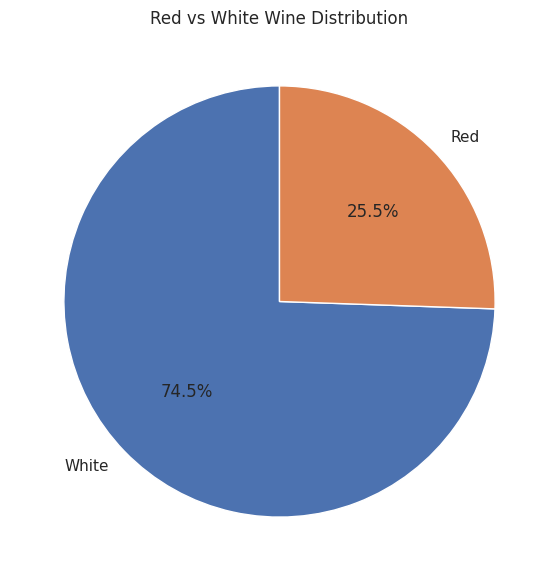

In [ ]:
wine_counts = df["wine_type"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    wine_counts,
    labels=wine_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Red vs White Wine Distribution")

plt.show()

In [ ]:
tree_data = df.groupby(
    ["wine_type", "quality"]
).size().reset_index(name="count")

fig = px.treemap(
    tree_data,
    path=["wine_type", "quality"],
    values="count",
    color="quality",
    color_continuous_scale="RdYlGn",
    title="Wine Quality Treemap"
)

fig.show()

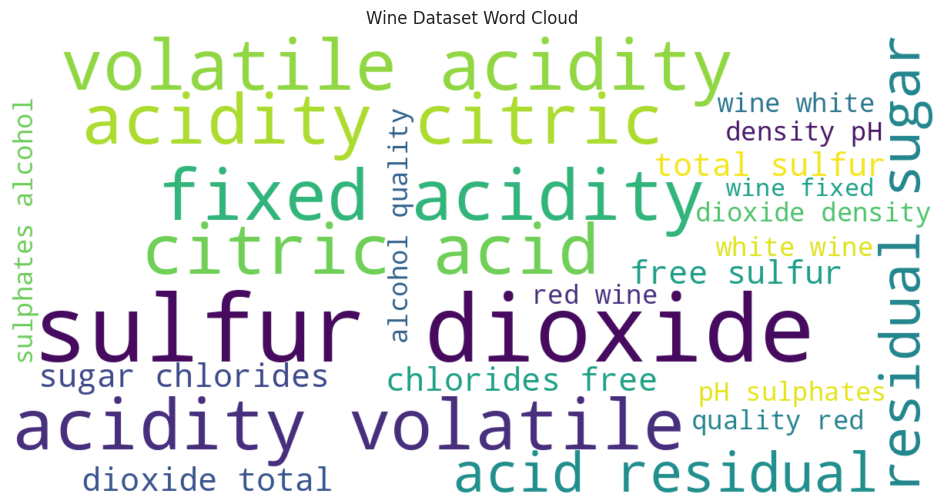

In [ ]:
text = " ".join([
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
    "quality",
    "red wine",
    "white wine"
] * 10)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis"
).generate(text)

plt.figure(figsize=(12,6))

plt.imshow(wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title("Wine Dataset Word Cloud")

plt.show()

In [ ]:
correlation = df.select_dtypes(
    include=np.number
).corr()["quality"].sort_values(
    ascending=False
)

print("Correlation with Wine Quality:")
print(correlation)

Correlation with Wine Quality:
quality                 1.000000
alcohol                 0.469422
citric acid             0.097954
free sulfur dioxide     0.054002
sulphates               0.041884
pH                      0.039733
total sulfur dioxide   -0.050296
residual sugar         -0.056830
fixed acidity          -0.080092
chlorides              -0.202137
volatile acidity       -0.265205
density                -0.326434
Name: quality, dtype: float64


In [ ]:
numerical_cols = df.select_dtypes(
    include=np.number
).columns

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(
        col,
        "Outliers:",
        len(outliers)
    )

fixed acidity Outliers: 304
volatile acidity Outliers: 279
citric acid Outliers: 143
residual sugar Outliers: 141
chlorides Outliers: 237
free sulfur dioxide Outliers: 44
total sulfur dioxide Outliers: 10
density Outliers: 3
pH Outliers: 49
sulphates Outliers: 163
alcohol Outliers: 1
quality Outliers: 183
